In [1]:
import pandas as pd
import numpy as np
from numpy._core.fromnumeric import std
from matplotlib import pyplot as plt
from statsmodels.stats.diagnostic import kstest_exponential

Data Exploration
1. You will need the file CleanedData-10-18-26.csv

In [2]:
data_set=pd.read_csv('CleanedData-10-18-26.csv',header=0)
print(data_set)
#Data read in correctly there are 13 attributes from original data + unnamed attribute from the CSV creation (see other Python file) and latitude and longitude


     Unnamed: 0  ID        Date Day of Week  Route         Stop-Street  \
0             0   1  2026-09-21           M      8  Halsted and Fulton   
1             1   2  2026-09-21           M      8  Halsted and Fulton   
2             2   3  2026-09-21           M      8  Halsted and Fulton   
3             3   4  2026-09-21           M      8  Halsted and Fulton   
4             4   5  2026-09-21           M      8  Halsted and Fulton   
..          ...  ..         ...         ...    ...                 ...   
97           97   5  2026-09-29           T      8  Halsted and Taylor   
98           98   6  2026-09-29           T      8  Halsted and Taylor   
99           99   7  2026-09-29           T      8  Halsted and Taylor   
100         100   8  2026-09-29           T    157  Taylor and Halsted   
101         101   9  2026-09-29           T      8  Halsted and Taylor   

     Stop-CTA ID Direction Ventra Time (Calculated when previous bus arrives)  \
0           5792         S    

Lets start with basic visualizations. These can help guide further exploratory research which in turn will guide what attributes we may want to include in our visualizations

In [3]:
#lets look at a basic distribution of bus lines, bareing in mind that we will collect more data
#Goal here is to see if our dataset is balanced
#Get a count by route line
route_count=data_set.groupby('Route').size()
print(route_count)


Route
8      15
20     12
22     10
36     10
56      8
66      3
96     10
146    10
147    10
157    14
dtype: int64


[8, 20, 22, 36, 56, 66, 96, 146, 147, 157]


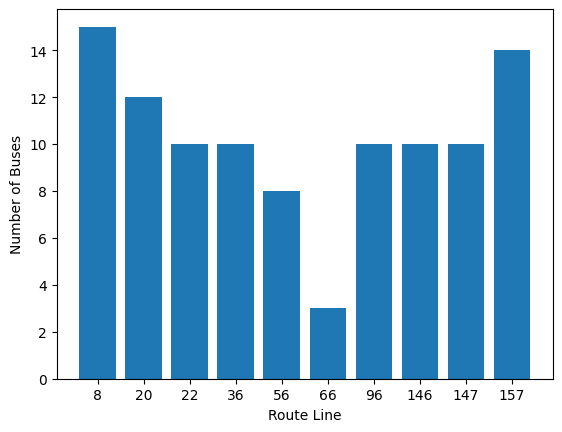

In [4]:
#Now lets plot bar charts
route_bins=set(data_set['Route'])
route_bins=list(route_bins)
route_bins.sort()
print(route_bins)
#But to stop numeric problem must cast to string https://stackoverflow.com/questions/49017002/bar-plot-based-on-list-of-string-values
route_bins_str=[str(x) for x in route_bins]
plt.bar(route_bins_str,route_count)
plt.xlabel('Route Line')
plt.ylabel('Number of Buses')
plt.show()

Now lets look at the range of time between buses, we'll print them out and visualize them

In [5]:
#Iterate between routes and get all of the time previous
#For each route
routes_dict={}
for i in route_bins:
  route_list_prev=[]
  for j in range(0,len(data_set)):
    if data_set.loc[j,'Route']==i:
      #999 handles the values of NA observations that began as we arrived to begin collecting data
      if data_set.loc[j,'Observation Previous (in mins)']==999:
        continue
      else:
        val_entry=int(data_set.loc[j,'Observation Previous (in mins)'])
        route_list_prev.append(val_entry)
    routes_dict[i]=route_list_prev
print(routes_dict)

{8: [2, 13, 10, 8, 3, 11, 9, 14, 10, 11, 8], 20: [5, 2, 16, 7, 0, 4, 9, 7, 13, 3], 22: [8, 2, 11, 12, 1, 0, 26, 26], 36: [10, 9, 3, 4, 20, 19, 21, 20], 56: [7, 1, 1, 10, 13, 2], 66: [21, 0, 1], 96: [30, 30, 29, 59, 29, 30, 60, 30], 146: [20, 20, 22, 19, 3, 2, 27, 3], 147: [14, 10, 13, 8, 3, 2, 28, 3], 157: [2, 2, 2, 20, 20, 20, 10, 20, 12, 24]}


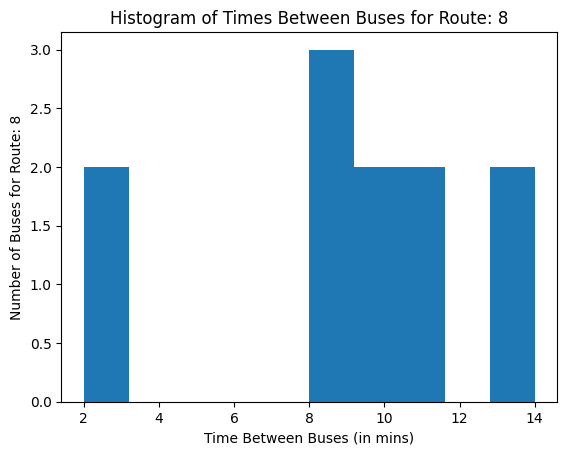

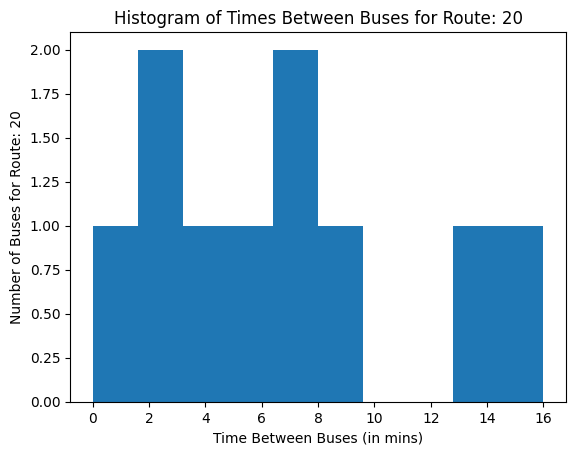

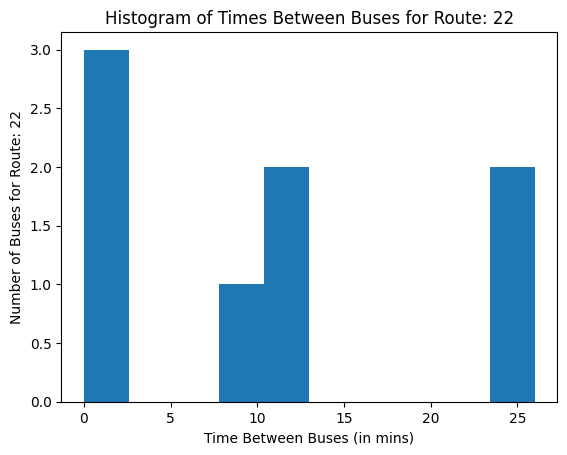

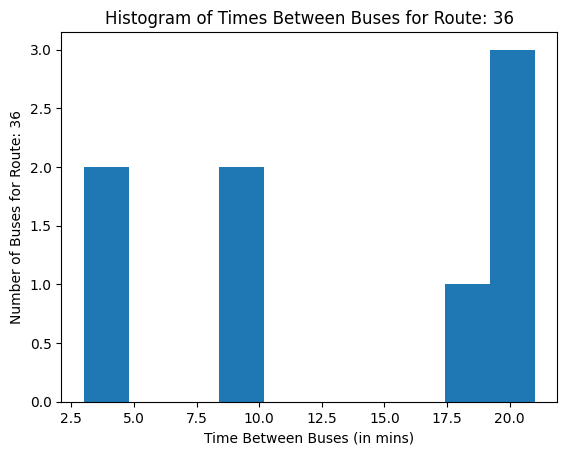

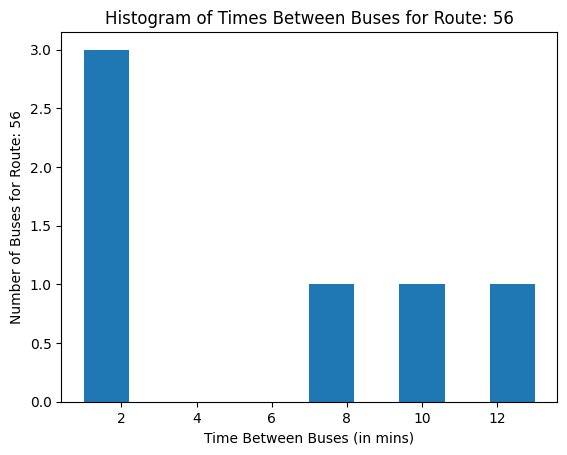

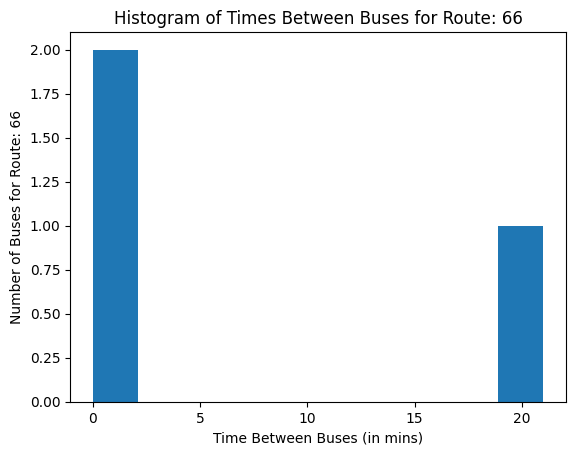

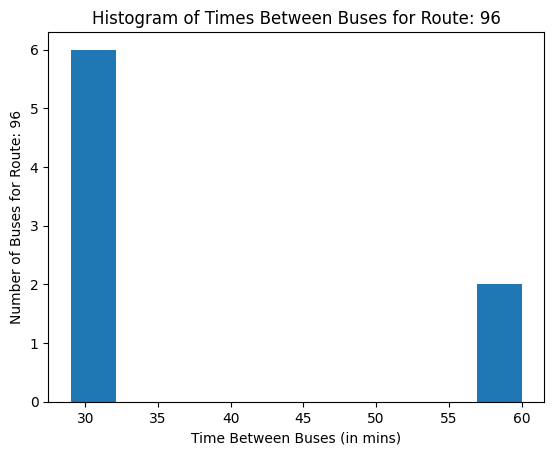

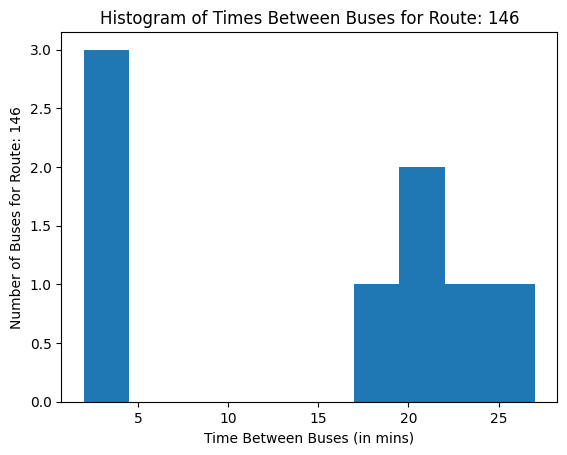

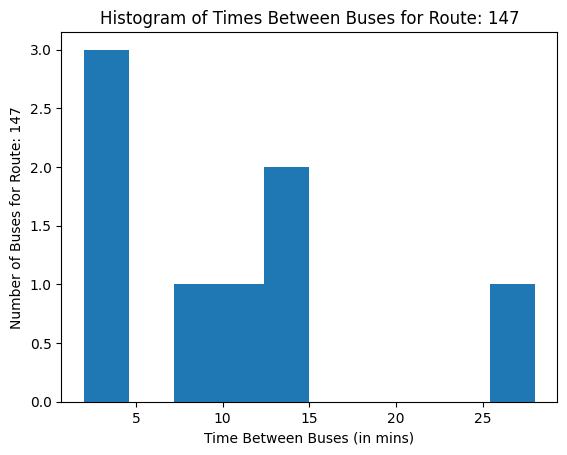

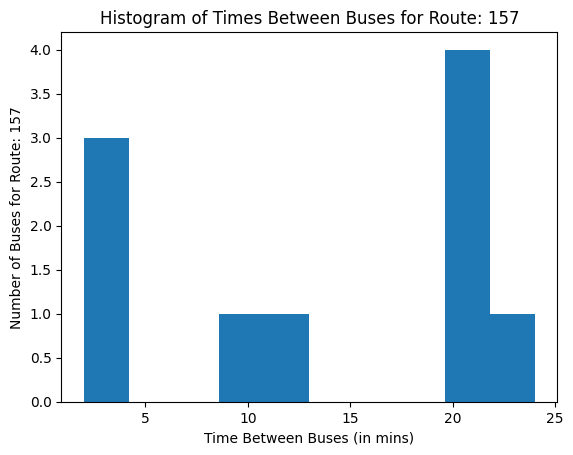

<Figure size 640x480 with 0 Axes>

In [6]:
#Make a histogram by each bus route
for i in range(0, len(routes_dict)):
  plt.hist(routes_dict[route_bins[i]])
  plt.title(f"Histogram of Times Between Buses for Route: {route_bins[i]}")
  plt.xlabel("Time Between Buses (in mins)")
  plt.ylabel(f"Number of Buses for Route: {route_bins[i]}")
  plt.figure()
plt.show()

Excluding Route 66 (see report), there is something interesting happening with:
-Route 96. This is a feeder bus for downtown bus lines. This line does not go into downtown and the group is still unsure whether it should be included or not
-Route 36. This bus line has is fairly uneven in its distribution of wait times. Sometimes buses arrived on time, but This is a northside to downtown bus
-Route 22 also showed interesting variation. There were times when buses arrived frequently, there were times when the headways exceeded the CTA limit
-Route 8 seems fairly distributed but its clear that a little less than half of buses are still coming close to exceed CTA headway limits


In [7]:
#Lets now look at summary statistics for the above routes
#Route 96:
route_96=list(routes_dict[96])
print(route_96)
mean_96=np.average(route_96)
print('The average time between buses for route 96 is:', mean_96, ' minutes')
std_dev_96=np.std(route_96)
print('The standard deviation for route 96 is:', std_dev_96, ' minutes')
#Walpole et al. (2017), "Proability and Statistics for Engineers and Scientists", 9th Ed, Pearson: USA.
#Source above used as guide
#Take a look at coefficient of variation
coeff_var_96=std_dev_96/mean_96
print("The coefficient of variation for Route 96 is: ", coeff_var_96)


[30, 30, 29, 59, 29, 30, 60, 30]
The average time between buses for route 96 is: 37.125  minutes
The standard deviation for route 96 is: 12.92707913644842  minutes
The coefficient of variation for Route 96 is:  0.34820415182352643


In [8]:
#Route 36--again this may not be included in the final research
route_36=list(routes_dict[36])
print(route_36)
mean_36=np.average(route_36)
print('The average time between buses for route 36 is:', mean_36, ' minutes')
std_dev_36=np.std(route_36)
print('The standard deviation for route 36 is:', std_dev_36, ' minutes')
#Coeff of variation
coeff_var_36=std_dev_36/mean_36
print("The coefficient of variation for Route 36 is: ", coeff_var_36)


[10, 9, 3, 4, 20, 19, 21, 20]
The average time between buses for route 36 is: 13.25  minutes
The standard deviation for route 36 is: 7.101936355670896  minutes
The coefficient of variation for Route 36 is:  0.5359951966544072


In [9]:
#Route 22
route_22=list(routes_dict[22])
print(route_22)
mean_22=np.average(route_22)
print('The average time between buses for route 22 is:', mean_22, ' minutes')
std_dev_22=np.std(route_22)
print('The standard deviation for route 22 is:', std_dev_22)
#Coefficient of variation
coeff_var_22=std_dev_22/mean_22
print("The coefficient of variation for Route 22 is: ", coeff_var_22)

[8, 2, 11, 12, 1, 0, 26, 26]
The average time between buses for route 22 is: 10.75  minutes
The standard deviation for route 22 is: 9.756408150543928
The coefficient of variation for Route 22 is:  0.9075728512133886


In [10]:
#Route 8
route_8=list(routes_dict[8])
print(route_8)
mean_8=np.average(route_8)
print('The average time between buses for route 8 is:', mean_8)
#Standard deviation
std_dev_8=np.std(route_8)
print('The standard deviation for route 8 is:', std_dev_8)
#Coefficient of variation
coeff_var_8=std_dev_8/mean_8
print("The coefficient of variation for Route 8 is: ", coeff_var_8)


[2, 13, 10, 8, 3, 11, 9, 14, 10, 11, 8]
The average time between buses for route 8 is: 9.0
The standard deviation for route 8 is: 3.541956316141483
The coefficient of variation for Route 8 is:  0.3935507017934981


In [11]:
#20
route_20=list(routes_dict[20])
print(route_20)
mean_20=np.average(route_20)
print('The average time between buses for route 20 is:', mean_20)
#Standard deviation
std_dev_20=np.std(route_20)
print('The standard deviation for route 20 is:', std_dev_20)
#Coefficient of variation
coeff_var_20=std_dev_20/mean_20
print("The coefficient of variation for Route 20 is: ", coeff_var_20)

[5, 2, 16, 7, 0, 4, 9, 7, 13, 3]
The average time between buses for route 20 is: 6.6
The standard deviation for route 20 is: 4.715930449020639
The coefficient of variation for Route 20 is:  0.7145349165182786


In [12]:

#56
route_56=list(routes_dict[56])
print(route_56)
mean_56=np.average(route_56)
print('The average time between buses for route 56 is:', mean_56)
std_dev_56=np.std(route_56)
print('The standard deviation for route 56 is:', std_dev_56)
#Coefficient of variation
coeff_var_56=std_dev_56/mean_56
print("The coefficient of variation for Route 56 is: ", coeff_var_56)

[7, 1, 1, 10, 13, 2]
The average time between buses for route 56 is: 5.666666666666667
The standard deviation for route 56 is: 4.6785562825394
The coefficient of variation for Route 56 is:  0.8256275792716589


In [13]:
#146
route_146=list(routes_dict[146])
print(route_146)
mean_146=np.average(route_146)
print('The average time between buses for route 146 is:', mean_146)
std_dev_146=np.std(route_146)
print('The standard deviation for route 146 is:', std_dev_146)
#Coefficient of variation
coeff_var_146=std_dev_146/mean_146
print("The coefficient of variation for Route 146 is: ", coeff_var_146)

[20, 20, 22, 19, 3, 2, 27, 3]
The average time between buses for route 146 is: 14.5
The standard deviation for route 146 is: 9.447221813845593
The coefficient of variation for Route 146 is:  0.6515325388859029


In [14]:
#147
route_147=list(routes_dict[147])
print(route_147)
mean_147=np.average(route_147)
print('The average time between buses for route 147 is:', mean_147)
std_dev_147=np.std(route_147)
print('The standard deviation for route 147 is:', std_dev_147)
#Coefficient of variation
coeff_var_147=std_dev_147/mean_147
print("The coefficient of variation for Route 147 is: ", coeff_var_147)

[14, 10, 13, 8, 3, 2, 28, 3]
The average time between buses for route 147 is: 10.125
The standard deviation for route 147 is: 8.02242949486002
The coefficient of variation for Route 147 is:  0.7923387155417304


In [15]:
#157
route_157=list(routes_dict[157])
print(route_157)
mean_157=np.average(route_157)
print('The average time between buses for route 157 is:', mean_157)
std_dev_157=np.std(route_157)
print('The standard deviation for route 157 is:', std_dev_157)
#Coefficient of variation
coeff_var_157=std_dev_157/mean_157
print("The coefficient of variation for Route 157 is: ", coeff_var_157)

[2, 2, 2, 20, 20, 20, 10, 20, 12, 24]
The average time between buses for route 157 is: 13.2
The standard deviation for route 157 is: 8.304215796810679
The coefficient of variation for Route 157 is:  0.6291072573341424


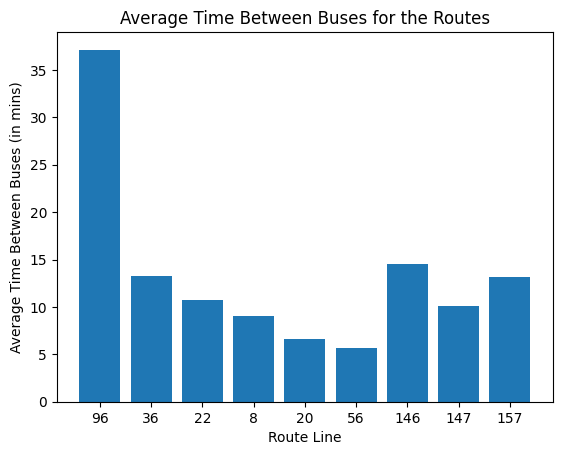

In [16]:
#Lets visualize this by plotting means
mean_interest_list=[mean_96,mean_36,mean_22,mean_8,mean_20,mean_56,mean_146, mean_147,mean_157]
route_interest_list=[str(96),str(36),str(22),str(8),str(20),str(56),str(146),str(147),str(157)]
plt.bar(route_interest_list,mean_interest_list)
plt.title('Average Time Between Buses for the Routes')
plt.xlabel('Route Line')
plt.ylabel('Average Time Between Buses (in mins)')
plt.show()

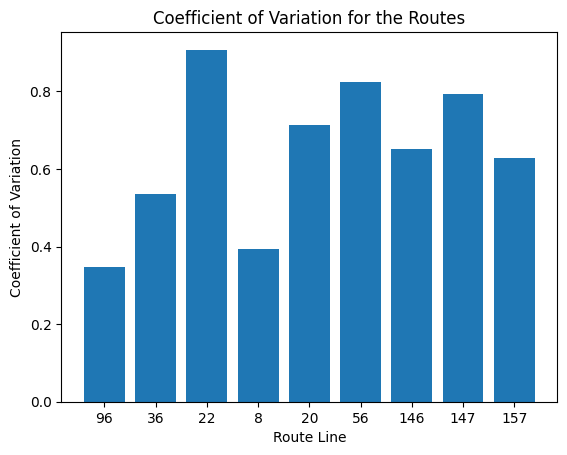

In [17]:
#Lets also plot the coefficient of variations
#The goal here is to see how close the headways per route are to the average headways per route
coeff_var_interest_list=[coeff_var_96,coeff_var_36,coeff_var_22,coeff_var_8,coeff_var_20,coeff_var_56,coeff_var_146,coeff_var_147,coeff_var_157]
plt.bar(route_interest_list,coeff_var_interest_list)
plt.title('Coefficient of Variation for the Routes')
plt.xlabel('Route Line')
plt.ylabel('Coefficient of Variation')
plt.show()

/tmp/ipykernel_1215/3364019795.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(line_times,labels=['Route: 96','36','22','8','20','56', '146', '147', '157'])


Text(0, 0.5, 'Time Between Buses (in mins)')

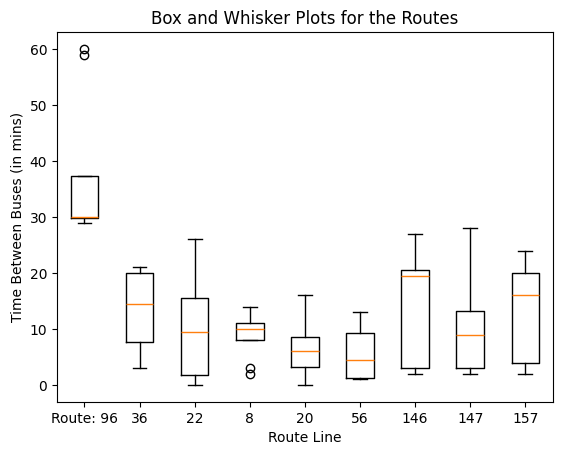

In [21]:
#Multiple box and whisker plots by line
line_times=[route_96,route_36,route_22,route_8,route_20,route_56,route_146,route_147,route_157]
plt.boxplot(line_times,labels=['Route: 96','36','22','8','20','56', '146', '147', '157'])
plt.title('Box and Whisker Plots for the Routes')
plt.xlabel('Route Line')
plt.ylabel('Time Between Buses (in mins)')

Comments : its interesting to note that on average buses on the northside to downtown actually have longer headways then those on the westside. Though the caveat is that the coefficient of variation (how closely bunched the bus are to the average headway) vary slightly more on Westside to downtown buses then northside to downtown buses. Looking at the distribution of wait times, shows median wait times that are fairly evenly distributed, with some outliers,especially Route 96. Overall though, N/S Buses appear to have longer median times as well. But given the small data size further exploration is needed. We'll examine this in more detail in the next section.

In [22]:
#Now lets see if these bus wait times fit an exponential distribution. The group is hoping to perhaps calculate the probability a bus arrives
#Waittimes usually follow exponential distribution (note the small sample size may affect results)
#We will do a Lilliefors KS Test--https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.kstest_exponential.html
#Route 96
print("Route 96")
ks_test_96=kstest_exponential(route_96,dist='exp',pvalmethod='table')
print(ks_test_96)
#Route 36
print("Route 30")
ks_test_36=kstest_exponential(route_36,dist='exp',pvalmethod='table')
print(ks_test_36)
#Route 22
print("Route 22")
ks_test_22=kstest_exponential(route_22,dist='exp',pvalmethod='table')
print(ks_test_22)
#Route 8
print("Route 8")
ks_test_8=kstest_exponential(route_8,dist='exp',pvalmethod='table')
print(ks_test_8)
#Route 20
print("Route 20")
ks_test_20=kstest_exponential(route_20,dist='exp',pvalmethod='table')
print(ks_test_20)
#Route 56
print("Route 56")
ks_test_56=kstest_exponential(route_56,dist='exp',pvalmethod='table')
print(ks_test_56)
#146
print("Route 146")
ks_test_146=kstest_exponential(route_146,dist='exp',pvalmethod='table')
print(ks_test_146)
#147
print("Route 147")
ks_test_147=kstest_exponential(route_147,dist='exp',pvalmethod='table')
print(ks_test_147)
#157
print("Route 157")
ks_test_157=kstest_exponential(route_157,dist='exp',pvalmethod='table')
print(ks_test_157)

Route 96
(np.float64(0.5421184629917519), np.float64(0.0009999999999998899))
Route 30
(np.float64(0.261637406878797), np.float64(0.3378017489811582))
Route 22
(np.float64(0.20523497850348651), np.float64(0.6683831817203982))
Route 8
(np.float64(0.4070695276746307), np.float64(0.0025408145232798623))
Route 20
(np.float64(0.1652635810597181), np.float64(0.7997539592922305))
Route 56
(np.float64(0.2092507646900139), np.float64(0.8001155258145124))
Route 146
(np.float64(0.3552729689742897), np.float64(0.055081120253565555))
Route 147
(np.float64(0.17924519170173198), np.float64(0.8221888290693732))
Route 157
(np.float64(0.2802251168997464), np.float64(0.15118424545570985))


With the exception of Route 96 and Route 8 all other Routes follow an exponential distribution. Note due to the small sample size it may be that all routes follow the classic exponential distribution (wait times). We will collect more data to cross checks

Now lets focus on ghost buses and Ventra inaccuracies by route. We will see how off these statistics are. Since we are looking at deltas we will look at all routes

In [23]:
#Ventra Time (Calculated when previous bus arrives)- Real Time (negative indicates early arrival). For this section we will look at all routes
print(data_set['Real Time'].dtype)
print(data_set['Ventra Time (Calculated when previous bus arrives)'].dtype)
#https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html
#https://www.geeksforgeeks.org/python/python-timedelta-total_seconds-method-with-example/
differences_by_line=[]
for i in range(0, len(data_set)):
  route_interest=data_set.loc[i,'Route']
  route_interest=int(route_interest)
  real_time=pd.to_datetime(data_set.loc[i,'Real Time'],format='%H:%M:%S')
  ventra_time=pd.to_datetime(data_set.loc[i,'Ventra Time (Calculated when previous bus arrives)'],format='%H:%M:%S')
  delta_value=(real_time-ventra_time).total_seconds()/60
  differences_by_line.append([route_interest,delta_value])
print(differences_by_line)




object
object
[[8, -5.0], [8, -17.0], [8, 1.0], [8, -1.0], [8, -1.0], [66, 0.0], [66, 1.0], [66, -12.0], [20, -3.0], [56, 0.0], [20, -1.0], [20, -6.0], [56, 3.0], [56, -5.0], [56, -14.0], [20, 3.0], [56, 1.0], [20, 7.0], [20, 3.0], [20, 3.0], [56, 1.0], [20, 0.0], [56, 1.0], [20, -1.0], [20, 3.0], [20, 6.0], [20, -1.0], [56, 3.0], [8, 0.0], [8, 2.0], [8, 0.0], [8, 0.0], [8, 4.0], [147, -2.0], [147, 1.0], [147, 1.0], [147, 1.0], [147, 0.0], [22, 1.0], [22, 1.0], [22, 0.0], [22, 2.0], [22, 0.0], [157, -1.0], [157, -1.0], [157, -1.0], [157, -1.0], [157, 0.0], [96, 1.0], [96, 1.0], [96, 0.0], [96, 0.0], [96, 0.0], [147, 0.0], [147, -9.0], [147, -8.0], [147, 0.0], [147, -7.0], [22, 0.0], [22, -9.0], [22, -12.0], [22, 0.0], [22, 14.0], [157, 0.0], [157, 0.0], [157, 0.0], [157, -10.0], [157, 0.0], [96, 1.0], [96, 0.0], [96, 0.0], [96, 0.0], [96, 0.0], [36, 1.0], [36, 1.0], [36, 0.0], [36, -7.0], [36, -13.0], [146, 1.0], [146, 1.0], [146, 1.0], [146, 3.0], [146, 2.0], [36, 1.0], [36, 1.0], [36

In [24]:
#Place into dictionary
delta_dict={}
routes_total=set(data_set['Route'])
routes_total=list(routes_total)
for i in range(0, len(routes_total)):
  route_interest=routes_total[i]
  route_list_delta=[]
  for j in range(0,len(differences_by_line)):
    if differences_by_line[j][0]==route_interest:
      route_list_delta.append(differences_by_line[j][1])
  delta_dict[route_interest]=route_list_delta
print(delta_dict)




{96: [1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0], 66: [0.0, 1.0, -12.0], 36: [1.0, 1.0, 0.0, -7.0, -13.0, 1.0, 1.0, 0.0, 1.0, 1.0], 8: [-5.0, -17.0, 1.0, -1.0, -1.0, 0.0, 2.0, 0.0, 0.0, 4.0, 1.0, 2.0, 2.0, 4.0, 3.0], 146: [1.0, 1.0, 1.0, 3.0, 2.0, 1.0, -8.0, -16.0, 15.0, -9.0], 147: [-2.0, 1.0, 1.0, 1.0, 0.0, 0.0, -9.0, -8.0, 0.0, -7.0], 20: [-3.0, -1.0, -6.0, 3.0, 7.0, 3.0, 3.0, 0.0, -1.0, 3.0, 6.0, -1.0], 22: [1.0, 1.0, 0.0, 2.0, 0.0, 0.0, -9.0, -12.0, 0.0, 14.0], 56: [0.0, 3.0, -5.0, -14.0, 1.0, 1.0, 1.0, 3.0], 157: [-1.0, -1.0, -1.0, -1.0, 0.0, 0.0, 0.0, 0.0, -10.0, 0.0, 0.0, 1.0, 0.0, 0.0]}


In [25]:
#Get average across each dictionary key
#https://www.geeksforgeeks.org/python/python-dictionary-values-mean/
#key values
delta_keys=delta_dict.keys()
delta_average_list=[]
#print(delta_keys)
for route, values in delta_dict.items():
    average_values = int(np.average(values))
    delta_average_list.append((route, average_values))
print(delta_average_list)


[(96, 0), (66, -3), (36, -1), (8, 0), (146, 0), (147, -2), (20, 1), (22, 0), (56, -1), (157, 0)]


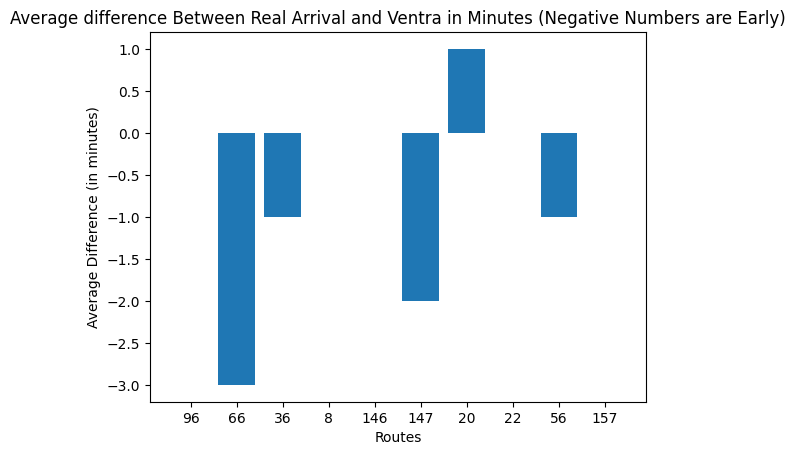

In [26]:
#Plot a bar chart
x_axis_list=[]
y_axis_list=[]
for i in range(0,len(delta_average_list)):
  x_axis_list.append(str(delta_average_list[i][0]))
  y_axis_list.append(delta_average_list[i][1])
plt.bar(x_axis_list,y_axis_list)
plt.title("Average difference Between Real Arrival and Ventra in Minutes (Negative Numbers are Early)")
plt.xlabel("Routes")
plt.ylabel("Average Difference (in minutes)")
plt.show()

/tmp/ipykernel_1215/2396104310.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(delta_dict.values(),labels=delta_dict.keys())


Text(0, 0.5, 'Time Between Buses (in mins)')

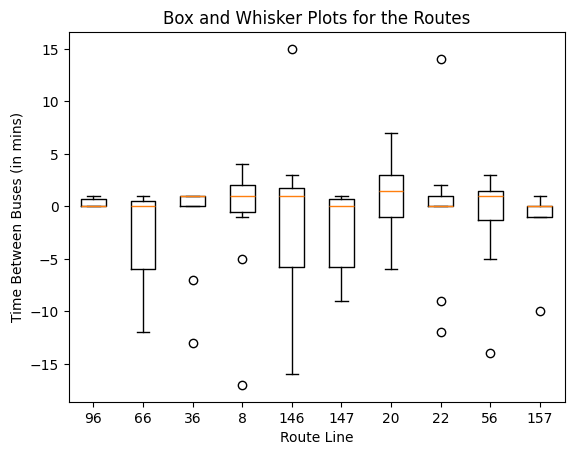

In [33]:
plt.boxplot(delta_dict.values(),labels=delta_dict.keys())
plt.title('Box and Whisker Plots for the Routes')
plt.xlabel('Route Line')
plt.ylabel('Time Between Buses (in mins)')

Interestingly enough 66 (which we don't have enough information, to make a conclusive determination), along with 147 exceed CTA Headway rules of being no more than 1 minute early.

Now lets look at N/S vs E/W buses to see if there are any major differences.

[96, 36, 22, 8, 20, 56, 146, 147, 157]
[96, 36, 22, 8, 20, 56, 146, 147, 157]
[np.float64(37.125), np.float64(13.25), np.float64(10.75), np.float64(9.0), np.float64(6.6), np.float64(5.666666666666667), np.float64(14.5), np.float64(10.125), np.float64(13.2)]
[37, 13, 10, 9, 14, 10]
[6, 5, 13]
15.5
8.0


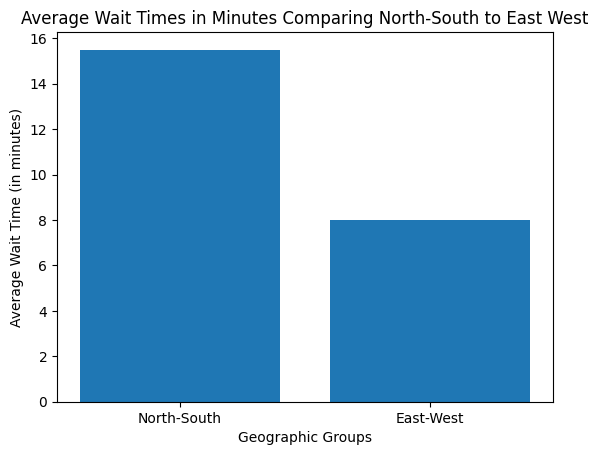

[(96, 0), (66, -3), (36, -1), (8, 0), (146, 0), (147, -2), (20, 1), (22, 0), (56, -1), (157, 0)]
[0, -1, 0, 0, -2, 0]
[-3, 1, -1, 0]
-0.5
-0.75


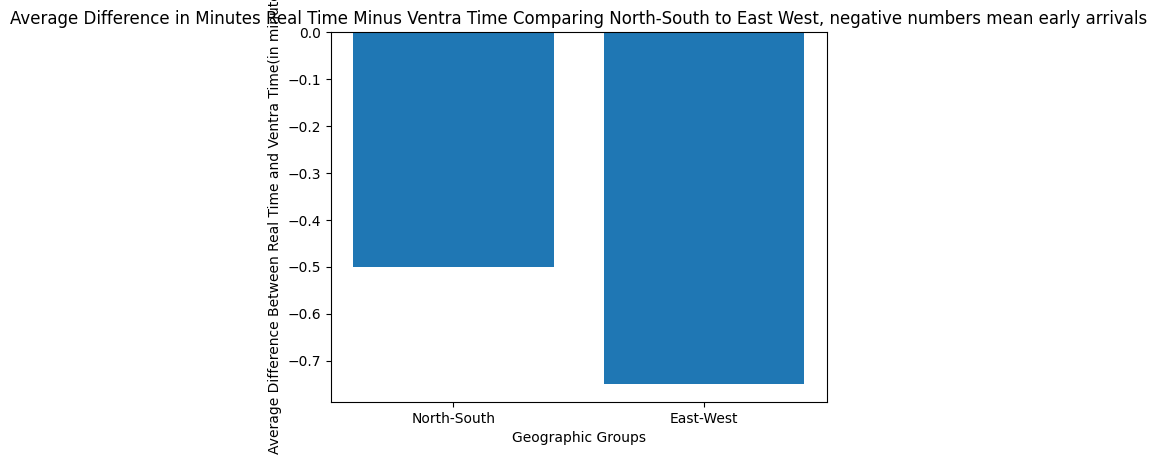

In [29]:
#Group buses into north south, east west
#Average headways--mean interest list
print(route_interest_list)
for i in range(0,len(route_interest_list)):
  route_interest_list[i]=int(route_interest_list[i])
print(route_interest_list)
print(mean_interest_list)
ns_average=[]
ew_average=[]

north_list=[96,36,22,8,146,147]

#Manually create
for i in range(0, len(route_interest_list)):
  if route_interest_list[i] in north_list:
    ns_average.append(int(mean_interest_list[i]))
  else:
    ew_average.append(int(mean_interest_list[i]))
print(ns_average)
print(ew_average)

#Now we'll average accross lists
ns_average_final=np.average(ns_average)
ew_average_final=np.average(ew_average)
print(ns_average_final)
print(ew_average_final)
geog_groups=['North-South','East-West']
average_geog=[ns_average_final,ew_average_final]

plt.bar(geog_groups,average_geog)
plt.title('Average Wait Times in Minutes Comparing North-South to East West')
plt.xlabel('Geographic Groups')
plt.ylabel('Average Wait Time (in minutes)')
plt.show()
#Delta average list
print(delta_average_list)
ns_delta=[]
ew_delta=[]
for i in range(0,len(delta_average_list)):
  if delta_average_list[i][0] in north_list:
    ns_delta.append(int(delta_average_list[i][1]))
  else:
    ew_delta.append(int(delta_average_list[i][1]))

print(ns_delta)
print(ew_delta)
ns_delta_final=np.average(ns_delta)
ew_delta_final=np.average(ew_delta)
print(ns_delta_final)
print(ew_delta_final)
geog_groups_delta=['North-South','East-West']
average_geog_delta=[ns_delta_final,ew_delta_final]
plt.bar(geog_groups_delta,average_geog_delta)
plt.title('Average Difference in Minutes Real Time Minus Ventra Time Comparing North-South to East West, negative numbers mean early arrivals')
plt.xlabel('Geographic Groups')
plt.ylabel('Average Difference Between Real Time and Ventra Time(in minutes)')
plt.show()

[[30, 30, 29, 59, 29, 30, 60, 30], [10, 9, 3, 4, 20, 19, 21, 20], [8, 2, 11, 12, 1, 0, 26, 26], [2, 13, 10, 8, 3, 11, 9, 14, 10, 11, 8], [20, 20, 22, 19, 3, 2, 27, 3], [14, 10, 13, 8, 3, 2, 28, 3]]
[[5, 2, 16, 7, 0, 4, 9, 7, 13, 3], [7, 1, 1, 10, 13, 2], [2, 2, 2, 20, 20, 20, 10, 20, 12, 24]]


/tmp/ipykernel_1215/3378918746.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_geog_wait,labels=['North-South','East-West'])


Text(0, 0.5, 'Time Between Buses (in mins)')

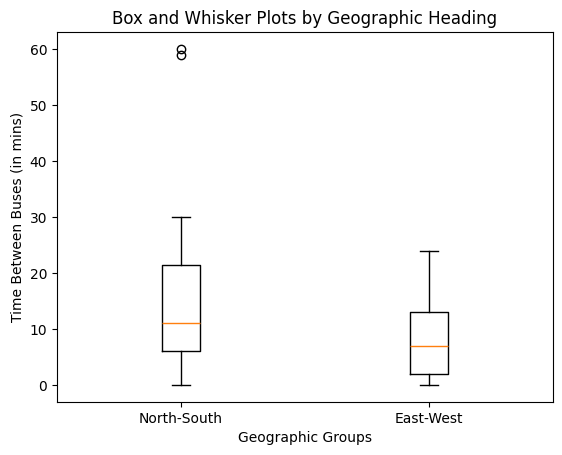

In [41]:
#Distribution of wait times by North-S East west
#Lets group wait times by geography
#North list
north_list=[96,36,22,8,146,147]
ns_waits=[route_96,route_36,route_22,route_8,route_146, route_147]
#Stack Overflow
ns_waits_final = [val for route in ns_waits for val in route]
ew_waits=[route_20,route_56,route_157]
ew_waits_final = [val for route in ew_waits for val in route]
box_geog_wait=[ns_waits_final,ew_waits_final]
print(ns_waits)
print(ew_waits)
plt.boxplot(box_geog_wait,labels=['North-South','East-West'])
plt.title('Box and Whisker Plots by Geographic Heading')
plt.xlabel('Geographic Groups')
plt.ylabel('Time Between Buses (in mins)')



{96: [1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0], 66: [0.0, 1.0, -12.0], 36: [1.0, 1.0, 0.0, -7.0, -13.0, 1.0, 1.0, 0.0, 1.0, 1.0], 8: [-5.0, -17.0, 1.0, -1.0, -1.0, 0.0, 2.0, 0.0, 0.0, 4.0, 1.0, 2.0, 2.0, 4.0, 3.0], 146: [1.0, 1.0, 1.0, 3.0, 2.0, 1.0, -8.0, -16.0, 15.0, -9.0], 147: [-2.0, 1.0, 1.0, 1.0, 0.0, 0.0, -9.0, -8.0, 0.0, -7.0], 20: [-3.0, -1.0, -6.0, 3.0, 7.0, 3.0, 3.0, 0.0, -1.0, 3.0, 6.0, -1.0], 22: [1.0, 1.0, 0.0, 2.0, 0.0, 0.0, -9.0, -12.0, 0.0, 14.0], 56: [0.0, 3.0, -5.0, -14.0, 1.0, 1.0, 1.0, 3.0], 157: [-1.0, -1.0, -1.0, -1.0, 0.0, 0.0, 0.0, 0.0, -10.0, 0.0, 0.0, 1.0, 0.0, 0.0]}
[[1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 3.0, 2.0, 1.0, -8.0, -16.0, 15.0, -9.0, -2.0, 1.0, 1.0, 1.0, 0.0, 0.0, -9.0, -8.0, 0.0, -7.0, 1.0, 1.0, 0.0, -7.0, -13.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 2.0, 0.0, 0.0, -9.0, -12.0, 0.0, 14.0, -5.0, -17.0, 1.0, -1.0, -1.0, 0.0, 2.0, 0.0, 0.0, 4.0, 1.0, 2.0, 2.0, 4.0, 3.0], [0.0, 3.0, -5.0, -14.0, 1.0, 1.0, 1.0, 3.

/tmp/ipykernel_1215/1280946048.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(delta_vals,labels=delta_cat)


Text(0, 0.5, 'Delta Time Between Real Time and Ventra Time (in mins)')

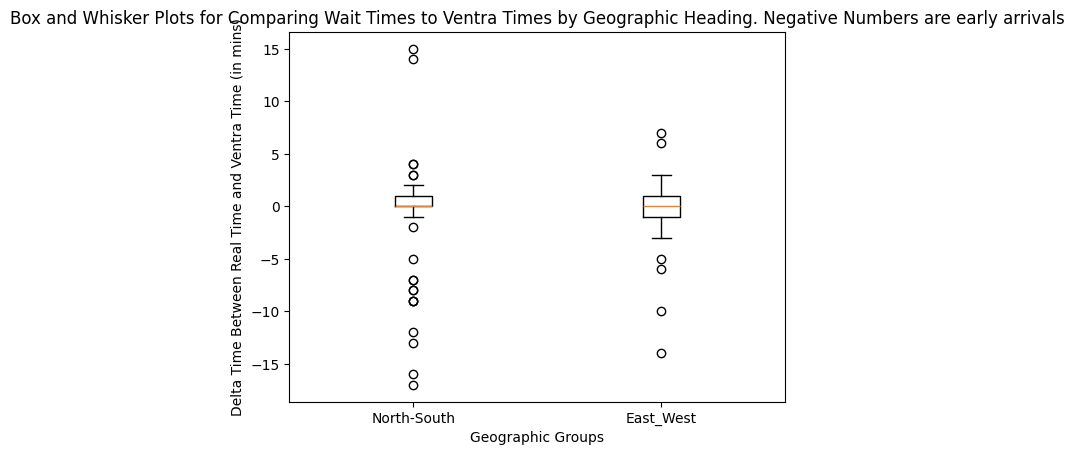

In [42]:
#Delta wait times vs ventra
#https://www.geeksforgeeks.org/python/get-a-subset-of-dict-in-python/

print(delta_dict)
keys_ns={96,36,22,8,146,147}
keys_ew={20,56,157}
ns_delta_dict={k: delta_dict[k] for k in keys_ns}
ew_delta_dict={k: delta_dict[k] for k in keys_ew}

ns_delta=[val for i in ns_delta_dict.values() for val in i]
ew_delta=[val for i in ew_delta_dict.values() for val in i]

delta_vals = [ns_delta, ew_delta]
delta_cat=['North-South','East_West']
print(delta_vals)
print(delta_cat)
plt.boxplot(delta_vals,labels=delta_cat)
plt.title('Box and Whisker Plots for Comparing Wait Times to Ventra Times by Geographic Heading. Negative Numbers are early arrivals')
plt.xlabel('Geographic Groups')
plt.ylabel('Delta Time Between Real Time and Ventra Time (in mins)')
#
